# Pitfall 2 — Survivorship bias

> *If you only study the companies that are still around, you are studying the winners —
> and then acting surprised that the strategy wins.*

Same three-act structure as the look-ahead notebook:

1. **The cheat** — an equal-weight portfolio built from "the stocks that exist today". It looks solid.
2. **The reveal** — the stock list itself was chosen with knowledge of the future.
3. **The fix** — the *same* portfolio, built from every stock that existed at the start, including
   the ones that later went bankrupt. Returns drop noticeably.

The engine (`src/backtest.py`) is untouched. The universe and the portfolio construction live in a
new, separate module, `src/universe.py`; the engine is only used to compute metrics on the
portfolio's NAV.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent / "src"))
from backtest import run_backtest
from universe import make_synthetic_universe, equal_weight_buy_and_hold

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams["figure.dpi"] = 110


def metrics(nav: pd.Series) -> pd.Series:
    # A NAV is just a price series: hold it at weight 1 and let the engine score it.
    return run_backtest(nav, pd.Series(1.0, index=nav.index)).summary()

## Why a synthetic universe?

Survivorship bias is about stocks that **no longer exist**. Free data sources — `yfinance`
included — mostly don't have their price histories (more on this in the real-data note at the end).
Rather than demonstrate the bias with data that is itself survivorship-biased, we generate a
universe where we know the full truth: every stock, every bankruptcy, and every stock's
*true* expected return.

**The model** (`src/universe.py`, fixed seed → fully reproducible):

- 200 stocks, business days 2015–2024, all starting at a price of 100.
- Daily log return of stock $i$:
  $\; r_{i,t} = \beta_i\, m_t + \alpha_i/252 + \sigma_i/\sqrt{252}\;\varepsilon_{i,t}$
  — a common market factor $m_t$ (7% drift, 16% vol), a stock-specific true alpha
  $\alpha_i \sim N(0, 4\%)$, beta $\beta_i \sim N(1, 0.25)$, and idiosyncratic vol $\sigma_i \in [20\%, 55\%]$.
- **Delisting rule:** the first day a stock closes below 10% of its starting price, it
  "goes bankrupt". Shareholders are paid a `recovery` fraction of that close (default **0** —
  equity is wiped out), and the stock stops trading.

This is deliberately simple — no mergers, no new listings, no fraud-style sudden collapses — but
it has the one feature that matters: **some companies that were investable on day 1 aren't there
on the last day.** (The dates are just labels. The synthetic market's ups and downs don't follow
real 2015–2024 history.)

In [2]:
uni = make_synthetic_universe(n_stocks=200, start="2015-01-01", end="2024-12-31", seed=42)

n_total = uni.prices.shape[1]
survivors = uni.survivors
delisted = uni.delist_date.dropna()
print(f"stocks at start:      {n_total}")
print(f"survived to the end:  {len(survivors)}")
print(f"delisted (bankrupt):  {len(delisted)}  ({len(delisted) / n_total:.0%})")

stocks at start:      200
survived to the end:  153
delisted (bankrupt):  47  (24%)


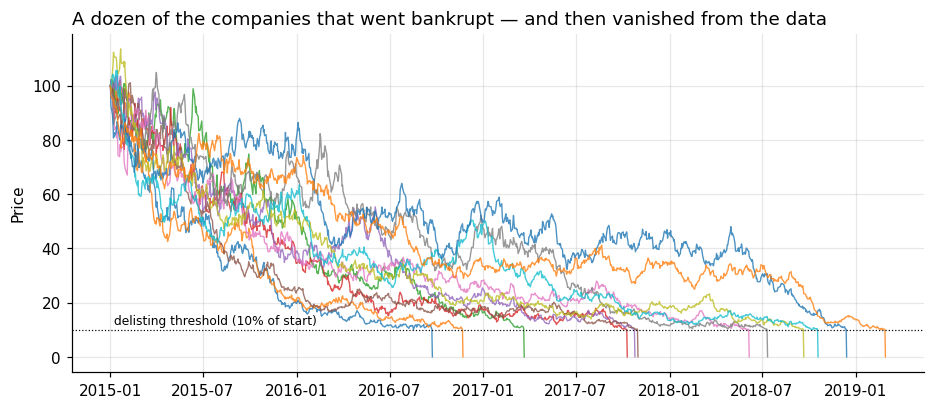

In [3]:
fig, ax = plt.subplots(figsize=(10, 4))
for t in delisted.sort_values().index[:12]:
    ax.plot(uni.prices[t], lw=0.9, alpha=0.8)
ax.axhline(10, color="black", ls=":", lw=0.8)
ax.text(uni.prices.index[5], 12, "delisting threshold (10% of start)", fontsize=8)
ax.set_title("A dozen of the companies that went bankrupt — and then vanished from the data", loc="left", fontsize=12)
ax.set_ylabel("Price")
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## The strategy: equal-weight buy-and-hold

The simplest portfolio possible, so the bias can't hide behind strategy logic:

> On the first trading day of 2015, put an equal amount of money into every stock in the universe.
> Never trade again.

If a company goes bankrupt, its position is settled at its final value (zero, by default) and that
money just sits as cash. The only question is **which stocks count as "the universe"**.

---
# Act 1 — The cheat

This is how most first backtests get built: take today's list of stocks (today's index members,
today's tickers on a screener), download their history, and run the strategy over the past ten years.
In our universe "today's list" means the stocks still trading on the last day.

In [4]:
nav_surv = equal_weight_buy_and_hold(uni.prices[survivors])
metrics(nav_surv).to_frame("survivors only")

,survivors only
CAGR,0.0478
Sharpe,0.3613
MaxDrawdown,-0.5544
Turnover,0.0004
FinalEquity,1.6223


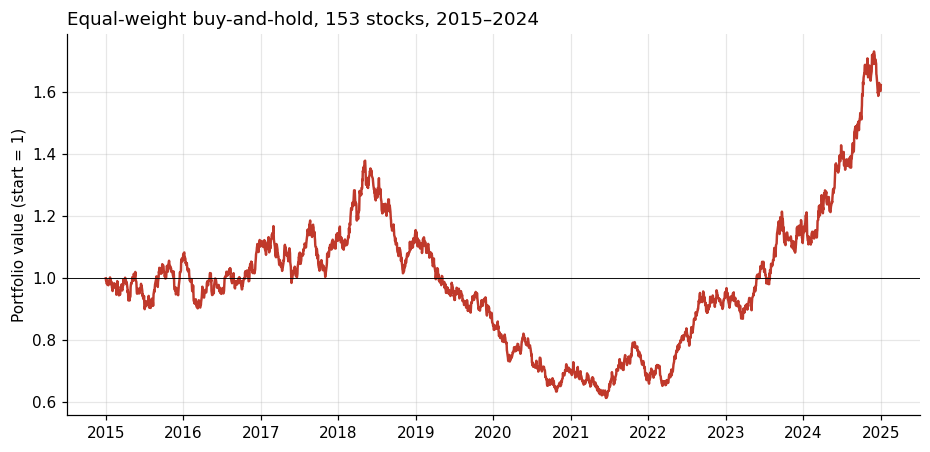

In [5]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(nav_surv, color="#c0392b", lw=1.6)
ax.axhline(1.0, color="black", lw=0.6)
ax.set_title(f"Equal-weight buy-and-hold, {len(survivors)} stocks, 2015–2024", loc="left", fontsize=12)
ax.set_ylabel("Portfolio value (start = 1)")
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

A positive return over the decade, a modest Sharpe, and a recovery from a long 2018–2021 slump. Nothing spectacular —
and that's exactly why survivorship bias is more dangerous than look-ahead bias: **it doesn't
produce an absurd number that sets off alarms.** It just quietly makes everything look a bit better
than it is.

---
# Act 2 — The reveal

### The universe was chosen in 2024

The portfolio claims to be formed in January 2015, but the list of stocks it holds was drawn up
in **December 2024**: "the stocks that are still trading". In 2015, no investor could have known
which 153 of the 200 companies would survive. Every stock that was going to go bankrupt was
silently removed before the backtest even started.

This is the same mistake as in Day 2, moved from the **time** dimension to the **cross-section**:

| | Day 2 — look-ahead | Day 3 — survivorship |
|---|---|---|
| What leaks from the future | the return of the day you're trading | which companies survive |
| Where it leaks | `position.shift(lag)` with `lag=0` | the stock list fed to the backtest |
| Symptom | absurd Sharpe, zero drawdown | quietly inflated returns, believable curve |

### Two ways the bias inflates returns

1. **The losses disappear.** Every bankruptcy is a −90% to −100% position. Dropping those stocks
   removes the worst outcomes from the portfolio.
2. **The survivors are selected on luck and quality.** Surviving is not random — it is
   correlated with having had a good path. Conditioning on "still alive in 2024" picks out stocks
   with higher true alpha, lower risk, and luckier shocks than the universe actually offered in 2015.

Because we generated the data, we can check channel 2 directly against the **true** parameters —
something you can never do with real data:

In [6]:
by_fate = (uni.params
           .assign(fate=np.where(uni.delist_date.isna(), "survived", "delisted"))
           .groupby("fate")[["alpha", "beta", "idio_vol"]]
           .mean())
by_fate.style.format({"alpha": "{:+.2%}", "beta": "{:.2f}", "idio_vol": "{:.1%}"})

,alpha,beta,idio_vol
fate,,,
delisted,-1.12%,1.03,43.7%
survived,+0.18%,1.00,35.9%


The companies that went bankrupt had a lower true alpha and much higher idiosyncratic volatility.
A survivors-only sample therefore doesn't just miss some bad outcomes; it gives a **biased picture of
what kind of stocks were available** — less risky and more profitable than they really were.

Channel 2 matters even when bankruptcies cost nothing. If we pretend shareholders got 50%, or even
100%, of the price on the day of delisting (`recovery`), the gap shrinks but doesn't go away:

In [7]:
rows = {}
for rec in [0.0, 0.5, 1.0]:
    u = make_synthetic_universe(seed=42, recovery=rec)
    rows[f"recovery = {rec:.0%}"] = {
        "CAGR survivors only": metrics(equal_weight_buy_and_hold(u.prices[u.survivors]))["CAGR"],
        "CAGR full universe":  metrics(equal_weight_buy_and_hold(u.prices))["CAGR"],
    }
sens = pd.DataFrame(rows).T
sens["gap (pp / yr)"] = (sens.iloc[:, 0] - sens.iloc[:, 1]) * 100
sens.style.format({"CAGR survivors only": "{:.2%}", "CAGR full universe": "{:.2%}", "gap (pp / yr)": "{:.2f}"})

,CAGR survivors only,CAGR full universe,gap (pp / yr)
recovery = 0%,4.78%,2.11%,2.68
recovery = 50%,4.78%,2.20%,2.58
recovery = 100%,4.78%,2.29%,2.49


The gap barely moves. **Most of the bias comes from *which* stocks you hold, not from how much the
bankrupt ones lost on the way out.** You can't fix survivorship bias by "assuming a reasonable
delisting loss" — you need the stocks themselves.

---
# Act 3 — The fix

Same strategy, same dates, same weighting. The only change: the universe is **every stock that
was listed on the first day**, which is the only list an investor in January 2015 could actually
have bought. Bankrupt stocks stay in the portfolio and are settled at their final value.

In [8]:
nav_full = equal_weight_buy_and_hold(uni.prices)
metrics(nav_full).to_frame("full universe")

,full universe
CAGR,0.0211
Sharpe,0.2081
MaxDrawdown,-0.5876
Turnover,0.0004
FinalEquity,1.2410


CAGR falls by more than half (4.8% → 2.1%), and Sharpe drops by about 40%. Nothing about the strategy changed; we just
stopped deleting its mistakes.

---
# Before / after

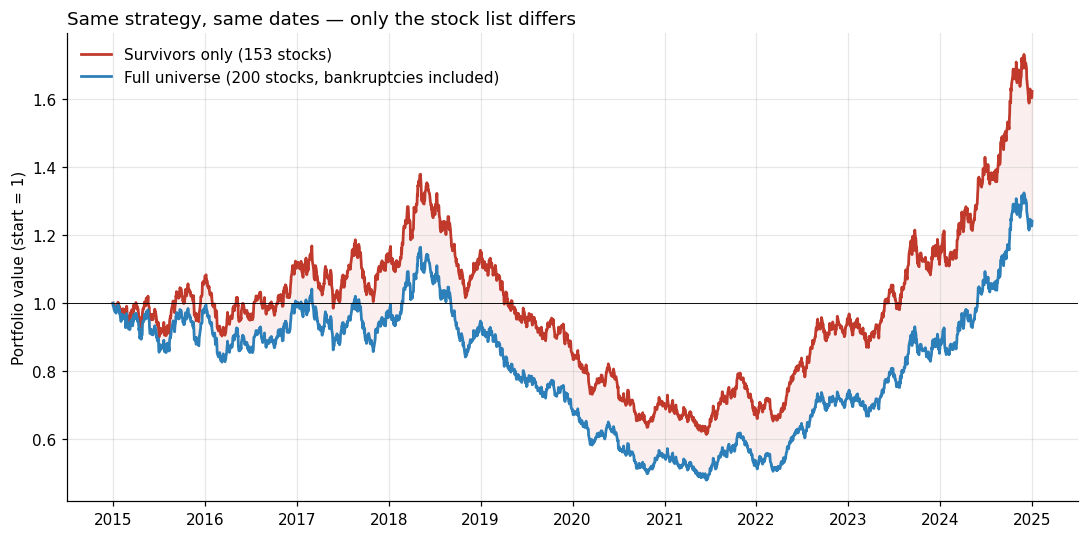

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(nav_surv, color="#c0392b", lw=1.8, label=f"Survivors only ({len(survivors)} stocks)")
ax.plot(nav_full, color="#2c7fb8", lw=1.8, label=f"Full universe ({n_total} stocks, bankruptcies included)")
ax.fill_between(nav_full.index, nav_full, nav_surv, color="#c0392b", alpha=0.08)
ax.axhline(1.0, color="black", lw=0.6)
ax.set_title("Same strategy, same dates — only the stock list differs", loc="left", fontsize=12)
ax.set_ylabel("Portfolio value (start = 1)")
ax.legend(loc="upper left", frameon=False)
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

In [10]:
comparison = pd.DataFrame({
    "Survivors only": metrics(nav_surv),
    "Full universe":  metrics(nav_full),
}).loc[["CAGR", "Sharpe", "MaxDrawdown", "FinalEquity"]].T

comparison.style.format({"CAGR": "{:.2%}", "Sharpe": "{:.2f}", "MaxDrawdown": "{:.1%}", "FinalEquity": "{:.2f}"})

,CAGR,Sharpe,MaxDrawdown,FinalEquity
Survivors only,4.78%,0.36,-55.4%,1.62
Full universe,2.11%,0.21,-58.8%,1.24


### Where the gap comes from: the universe shrinks over time

The shaded area above isn't spread evenly. It opens up as companies drop out. The chart below
shows how many of the original 200 stocks are still listed on each date. A survivors-only backtest
quietly assumes this line is flat at the end value from day one.

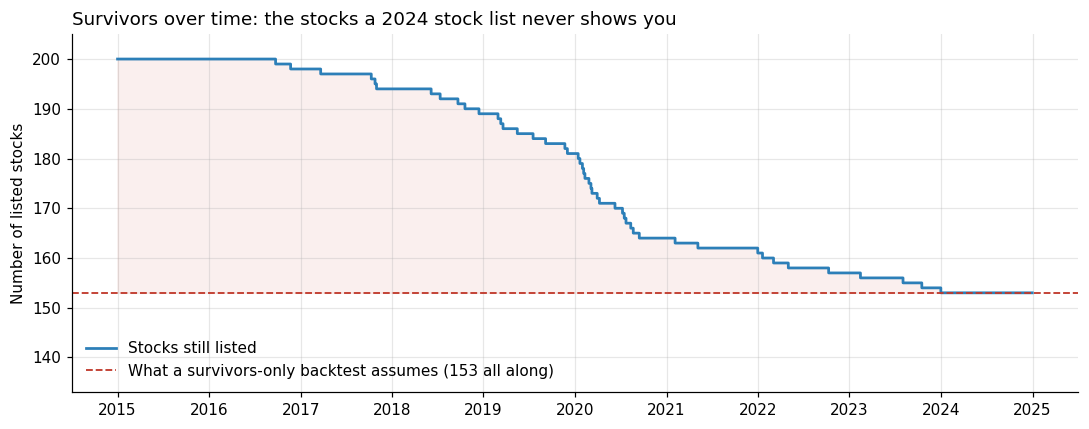

,2016,2017,2018,2019,2020,2021,2022,2023,2024
bankruptcies per year,2,4,5,8,17,3,4,3,1


In [11]:
alive = uni.alive_count()

fig, ax = plt.subplots(figsize=(10, 4))
ax.step(alive.index, alive, where="post", color="#2c7fb8", lw=1.8, label="Stocks still listed")
ax.axhline(len(survivors), color="#c0392b", ls="--", lw=1.2,
           label=f"What a survivors-only backtest assumes ({len(survivors)} all along)")
ax.fill_between(alive.index, len(survivors), alive, step="post", color="#c0392b", alpha=0.08)
ax.set_ylim(len(survivors) - 20, n_total + 5)
ax.set_title("Survivors over time: the stocks a 2024 stock list never shows you", loc="left", fontsize=12)
ax.set_ylabel("Number of listed stocks")
ax.legend(loc="lower left", frameon=False)
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

delisted.dt.year.value_counts().sort_index().rename("bankruptcies per year").to_frame().T

Bankruptcies cluster in the synthetic market's 2019–2021 slump, the same way defaults cluster in
real downturns: a bad market pushes the weakest companies over the edge. So the survivors-only
backtest is most wrong exactly when it matters, in the crisis.

---
# Is seed 42 just a lucky draw?

A single synthetic universe could be a fluke. Re-run the whole experiment on 100 independently
generated universes (seeds 0–99) and look at the survivors-minus-full CAGR gap each time.

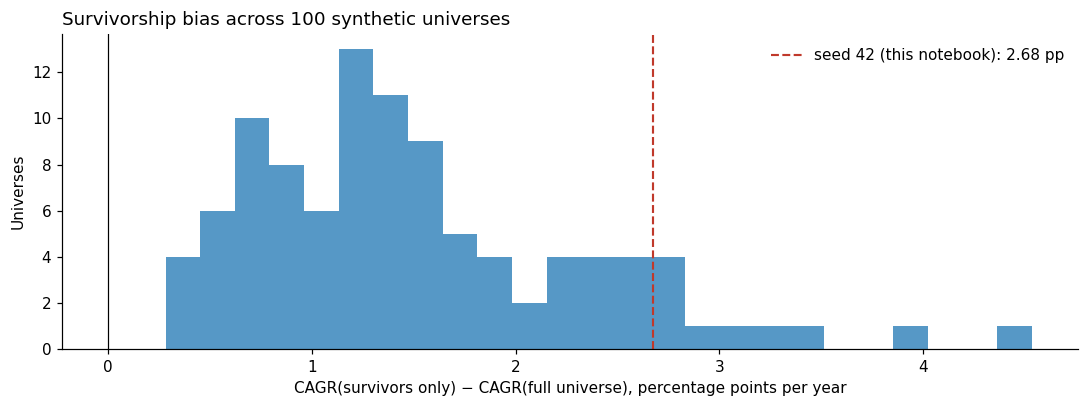

,delisted_share,gap_pp
mean,13.6%,1.52
50%,12.5%,1.37
min,2.5%,0.28
max,40.0%,4.53


In [12]:
def cagr(nav):
    return nav.iloc[-1] ** (252 / len(nav)) - 1

mc = []
for s in range(100):
    u = make_synthetic_universe(seed=s)
    mc.append({
        "seed": s,
        "delisted_share": u.delist_date.notna().mean(),
        "gap_pp": 100 * (cagr(equal_weight_buy_and_hold(u.prices[u.survivors]))
                         - cagr(equal_weight_buy_and_hold(u.prices))),
    })
mc = pd.DataFrame(mc).set_index("seed")

seed42_gap = 100 * (cagr(nav_surv) - cagr(nav_full))
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.hist(mc["gap_pp"], bins=25, color="#2c7fb8", alpha=0.8)
ax.axvline(0, color="black", lw=0.8)
ax.axvline(seed42_gap, color="#c0392b", ls="--", lw=1.4, label=f"seed 42 (this notebook): {seed42_gap:.2f} pp")
ax.set_title("Survivorship bias across 100 synthetic universes", loc="left", fontsize=12)
ax.set_xlabel("CAGR(survivors only) − CAGR(full universe), percentage points per year")
ax.set_ylabel("Universes")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

mc.describe().loc[["mean", "50%", "min", "max"]].style.format({"delisted_share": "{:.1%}", "gap_pp": "{:.2f}"})

The gap is positive in **every** universe, so the survivors-only backtest always flatters the
strategy. Seed 42 sits on the high side: it has more bankruptcies than average, which makes the gap
larger than the typical draw. The typical bias in this setup is about **1.5 percentage points
of CAGR per year**. That doesn't sound like much until you compound it over a decade, or until you
notice that it's comparable to the edge many real strategies claim to have.

---
# Note on real data: why point-in-time universes are hard to get

This notebook uses synthetic data on purpose. Running it on real stocks shows how hard the
honest version is, because the obvious free data is survivorship-biased itself.

**1. Free price sources mostly forget dead companies.** `yfinance` is keyed by *current* ticker
symbols. Ask it for a company that was delisted after bankruptcy or absorbed in a merger and you
usually get an empty frame and a "possibly delisted" warning. Tickers also get **reused**: the same
symbol can belong to a completely different company today. A universe assembled from
"tickers that `yfinance` can download" is a survivors-only universe by construction.

**2. "Today's S&P 500" is a survivors list.** Index membership changes every year: companies are
added after they've done well and removed after they've done badly, been acquired or gone
bankrupt. Backtesting on the current constituents over the past 10 years combines survivorship
bias with a second look-ahead: you're buying companies *because* they later grew big enough to
join the index.

**3. What doing it properly takes:**

- **CRSP** (via WRDS, mostly available through university subscriptions) is the academic
  standard. It has every US-listed stock including dead ones, permanent company identifiers that
  survive ticker changes, and **delisting returns**. Even there, delisting returns used to be
  missing for many performance-related delistings. Shumway (1997, *Journal of Finance*, "The
  Delisting Bias in CRSP Data") showed that ignoring them biases returns upward, and estimated
  the missing returns at roughly −30%.
- **Commercial vendors** (e.g. Norgate Data, Sharadar via Nasdaq Data Link, Compustat) sell
  survivorship-free price data with historical index constituents. They cost money, and that
  cost is part of the point.
- **A free approximation:** Wikipedia's *List of S&P 500 companies* page includes a table of
  constituent changes with the date of each addition and removal. Starting from today's list and
  walking the changes **backwards** rebuilds approximate point-in-time membership for any past
  date. The limits: the change log is less complete for earlier years, and you still need prices
  for the removed companies, which brings you back to problem 1.

In other words, **the hardest part of an honest cross-sectional backtest is usually the data, not
the strategy.** Survivorship-free data is expensive because it has to record what no longer
exists, and free data doesn't keep that.

---
# Takeaways

- **Survivorship bias is look-ahead bias in the cross-section.** Picking the universe with
  today's knowledge leaks the future just as surely as `lag=0` does. It's only harder to see.
- **It doesn't look like a bug.** Day 2's cheat gave a Sharpe of 13. This one gives a believable
  curve that is a bit too good, which is much more likely to make it into a real decision.
- **It's mostly selection, not just missing losses.** Even with full recovery at delisting, the
  survivors were the stocks with better alpha, lower risk and better luck. Assuming a delisting
  haircut doesn't fix that. Only including the dead stocks does.
- **The fix is a data question:** for every date, use the universe *as it was known on that
  date*. On real data, that means point-in-time constituents and price histories for the
  companies that died.